# TP6 – Réseaux Récurrents : RNN, LSTM et LSTM Bidirectionnel

In [1]:
# Calcul numérique
import numpy as np
# Manipulation de tableaux / DataFrame
import pandas as pd
# Visualisation
import matplotlib.pyplot as plt
# Outils système pour gérer le chemin du fichier
import os
# Pour extraire le fichier ZIP
import zipfile
# Normalisation
from sklearn.preprocessing import MinMaxScaler
# Métriques
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
# Modèles Keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN, LSTM, GRU, Dense
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import get_file

# PARTIE I : Q1 – Chargement du dataset Jena Climate

In [2]:
# Q1)  URL officielle du dataset Jena Climate au format ZIP
url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/jena_climate_2009_2016.csv.zip"
# Télécharger le ZIP
zip_path = get_file(
    fname="jena_climate_2009_2016.csv.zip",
    origin=url,
    extract=False
)
# Dossier où le ZIP a été téléchargé
extract_dir = os.path.dirname(zip_path)
# Extraire le contenu du ZIP
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_dir)
# Chemin du CSV extrait
csv_path = os.path.join(extract_dir, "jena_climate_2009_2016.csv")
# Lire le CSV
df = pd.read_csv(csv_path)
# Affichage des 5 premières lignes
print(df.head())
# Taille du dataset
print("Shape du DataFrame :", df.shape)
# Les noms de colonnes
print("Colonnes :")
print(df.columns.tolist())

             Date Time  p (mbar)  T (degC)  Tpot (K)  Tdew (degC)  rh (%)  \
0  01.01.2009 00:10:00    996.52     -8.02    265.40        -8.90    93.3   
1  01.01.2009 00:20:00    996.57     -8.41    265.01        -9.28    93.4   
2  01.01.2009 00:30:00    996.53     -8.51    264.91        -9.31    93.9   
3  01.01.2009 00:40:00    996.51     -8.31    265.12        -9.07    94.2   
4  01.01.2009 00:50:00    996.51     -8.27    265.15        -9.04    94.1   

   VPmax (mbar)  VPact (mbar)  VPdef (mbar)  sh (g/kg)  H2OC (mmol/mol)  \
0          3.33          3.11          0.22       1.94             3.12   
1          3.23          3.02          0.21       1.89             3.03   
2          3.21          3.01          0.20       1.88             3.02   
3          3.26          3.07          0.19       1.92             3.08   
4          3.27          3.08          0.19       1.92             3.09   

   rho (g/m**3)  wv (m/s)  max. wv (m/s)  wd (deg)  
0       1307.75      1.03        

## Q2 – Extraction de la variable cible T (degC)

In [3]:
# Q2)  On garde uniquement la température
data = df["T (degC)"].values.reshape(-1, 1)
# Vérification
print("Shape de la série univariée :", data.shape)

Shape de la série univariée : (420551, 1)


### Réponse Q2 – Pourquoi on transforme data au format (n, 1) avec reshape(-1,1) ?

Le `MinMaxScaler` de scikit-learn attend un tableau **2D** de forme `(n_samples, n_features)`.  
Avec `n_features=1` (température uniquement), il faut donc passer de la forme `(420551,)` à `(420551, 1)`.

De même, les couches récurrentes de Keras (LSTM, RNN,..) traitent des tenseurs de forme `(Nb de séquences, timesteps, features)`, donc le format `(n, 1)` facilite la construction des séquences avec la bonne dimension `features=1`.

## Q3 – Division temporelle des données (70 / 15 / 15)

In [4]:
# Q3) SPLIT TRAIN / VAL / TEST SANS SHUFFLE ET ENCHAINÉ DANS LE TEMPS
# Nombre total d'observations
n = len(data)
# 70% train, 15% validation, 15% test
train_size = int(n * 0.70)
val_size = int(n * 0.15)
# Découpage chronologique
train_data = data[:train_size]
val_data = data[train_size:train_size + val_size]
test_data = data[train_size + val_size:]
# Vérification
print("Train :", train_data.shape)
print("Validation :", val_data.shape)
print("Test :", test_data.shape)

Train : (294385, 1)
Validation : (63082, 1)
Test : (63084, 1)


## Q4 – Normalisation MinMaxScaler

In [5]:
# Q4) Création du scaler
scaler = MinMaxScaler()
# On ajuste le scaler uniquement sur le train
train_scaled = scaler.fit_transform(train_data)
# On applique le même scaler à val et test
val_scaled = scaler.transform(val_data)
test_scaled = scaler.transform(test_data)
# Vérification
print("Train scaled min/max :", train_scaled.min(), train_scaled.max())

Train scaled min/max : 0.0 1.0


## Q5 – Fonction create_sequences_multistep
- **`lookback`** = nombre de pas de temps passés utilisés comme entrée
- **`horizon`** = nombre de pas de temps futurs à prédire en sortie

Choix retenus :
- `lookback = 72` → 72 × 10 min = **720 minutes = 12 heures** d'historique
- `horizon  = 10` → prédiction de **10 pas futurs ** (100 minutes)

In [6]:
def create_sequences_multistep(data, lookback, horizon):
    X = []
    y = []
    # On parcourt la série
    for i in range(len(data) - lookback - horizon + 1):
        # Fenêtre passée
        x_seq = data[i : i + lookback]
        # Les valeurs futures à prédire
        y_seq = data[i + lookback : i + lookback + horizon]
        # Ajouter la fenêtre d'entrée
        X.append(x_seq)
        # Ajouter les sorties futures aplaties
        y.append(y_seq.flatten())
    # Convertir en tableaux numpy
    X = np.array(X)
    y = np.array(y)

    return X, y

In [7]:
lookback = 72
horizon = 10
# Création des séquences
X_train, y_train = create_sequences_multistep(train_scaled, lookback, horizon)
X_val, y_val = create_sequences_multistep(val_scaled, lookback, horizon)
X_test, y_test = create_sequences_multistep(test_scaled, lookback, horizon)

## Q6)– Affichage des dimensions de X_train et y_train.





In [8]:
# Q6) Vérification des shapes
print("X_train :", X_train.shape)
print("y_train :", y_train.shape)
print("X_val   :", X_val.shape)
print("y_val   :", y_val.shape)
print("X_test  :", X_test.shape)
print("y_test  :", y_test.shape)

X_train : (294304, 72, 1)
y_train : (294304, 10)
X_val   : (63001, 72, 1)
y_val   : (63001, 10)
X_test  : (63003, 72, 1)
y_test  : (63003, 10)


**Interprétation :**

- **`X_train`** a la forme `(n_séquences, lookback, n_features)` = `(294304, 72, 1)` :
  - Chaque ligne est une fenêtre glissante de **72 pas de temps** (12 heures de passé)
  - Le modèle lit ces 72 mesures pour apprendre à prédire le futur

- **`y_train`** a la forme `(n_séquences, horizon)` = `(294304, 10)` :
  - **Une ligne de `y_train`** représente les **10 valeurs futures de température** normalisées que le modèle doit prédire.
  - C'est une architecture **many-to-many** (séquence → plusieurs sorties)

In [9]:
print("Exemple X_train[0]")
print("Shape :", X_train[0].shape)
print("Premières valeurs :", X_train[0][:5])

print("Exemple y_train[0]")
print("Shape :", y_train[0].shape)
print("Valeurs :", y_train[0])

Exemple X_train[0]
Shape : (72, 1)
Premières valeurs : [[0.25462884]
 [0.24800408]
 [0.24630542]
 [0.24970273]
 [0.2503822 ]]
Exemple y_train[0]
Shape : (10,)
Valeurs : [0.27586207 0.27705113 0.27857992 0.28027858 0.28537455 0.29081026
 0.29182945 0.29301852 0.29064039 0.28945133]



Une ligne de y_train, par exemple y_train[0], représente : la fenêtre des 10 observations futures à prédire, juste après la fenêtre passée contenue dans X_train[0]. Donc :

*  X_train[0] contient les valeurs des instants t-72 à t
*  y_train[0] contient les valeurs cibles des instants t+1 à t+10

C’est donc un problème de prévision multistep : on ne prédit pas une seule valeur future, mais un bloc de 10 valeurs futures.

### Q7 – Construction des modèles : SimpleRNN, LSTM et LSTM Bidirectionnel

In [10]:
# Q7) Construction des modèles
def build_rnn_model(lookback, horizon):
    model = Sequential()
    model.add(SimpleRNN(64, input_shape=(lookback, 1)))
    model.add(Dense(horizon))
    model.compile(optimizer="adam", loss="mse")
    return model

def build_lstm_model(lookback, horizon):
    model = Sequential()
    model.add(LSTM(64, input_shape=(lookback, 1)))
    model.add(Dense(horizon))
    model.compile(optimizer="adam", loss="mse")
    return model

from tensorflow.keras.layers import Bidirectional

def build_bilstm_model(lookback, horizon):
    model = Sequential()
    model.add(Bidirectional(LSTM(64), input_shape=(lookback, 1)))
    model.add(Dense(horizon))
    model.compile(optimizer="adam", loss="mse")
    return model

In [11]:
model_rnn = build_rnn_model(lookback, horizon)
model_lstm = build_lstm_model(lookback, horizon)
model_bilstm = build_bilstm_model(lookback, horizon)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/bidirectional.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [12]:
early_stop = EarlyStopping(
    monitor="val_loss",          # surveiller la loss de validation
    patience=7,                  # attendre 7 epochs sans amélioration
    restore_best_weights=True    # restaurer les meilleurs poids
)

In [13]:
# Entraînement RNN
history_rnn = model_rnn.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 84s 18ms/step - loss: 9.5981e-04 - val_loss: 2.2712e-04
Epoch 2/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 86s 19ms/step - loss: 2.1650e-04 - val_loss: 2.1147e-04
Epoch 3/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 81s 18ms/step - loss: 1.9827e-04 - val_loss: 1.8889e-04
Epoch 4/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 83s 18ms/step - loss: 1.8923e-04 - val_loss: 1.9686e-04
Epoch 5/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 82s 18ms/step - loss: 1.8706e-04 - val_loss: 1.8809e-04
Epoch 6/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 82s 18ms/step - loss: 1.8518e-04 - val_loss: 1.9743e-04
Epoch 7/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 81s 18ms/step - loss: 1.8690e-04 - val_loss: 2.4480e-04
Epoch 8/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 82s 18ms/step - loss: 1.8968e-04 - val_loss: 1.8372e-04
Epoch 9/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 81s 18ms/step - loss: 1.9164e-04 - val_loss: 1.9314e-04
Epoch 10/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 81s 18ms/step - loss: 1.9061e-04 - val_loss: 1.8480e-04
Epoch 11/20
4599/45

In [14]:
# Entraînement LSTM
history_lstm = model_lstm.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20, batch_size=64,
    callbacks=[early_stop],
    verbose=1 )

# Entraînement LSTM Bidirectionnel
# history_bilstm = model_bilstm.fit(
#    X_train, y_train,
#    validation_data=(X_val, y_val),
#    epochs=20, batch_size=64,
#    callbacks=[early_stop],
#    verbose=1 )

Epoch 1/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 224s 48ms/step - loss: 9.6209e-04 - val_loss: 2.5949e-04
Epoch 2/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 209s 46ms/step - loss: 2.2239e-04 - val_loss: 1.9333e-04
Epoch 3/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 264s 46ms/step - loss: 1.9296e-04 - val_loss: 1.8623e-04
Epoch 4/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 265s 47ms/step - loss: 1.7992e-04 - val_loss: 1.7691e-04
Epoch 5/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 213s 46ms/step - loss: 1.7356e-04 - val_loss: 1.7499e-04
Epoch 6/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 240s 52ms/step - loss: 1.7177e-04 - val_loss: 1.7319e-04
Epoch 7/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 228s 49ms/step - loss: 1.6930e-04 - val_loss: 1.8147e-04
Epoch 8/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 254s 48ms/step - loss: 1.6858e-04 - val_loss: 1.6748e-04
Epoch 9/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 216s 47ms/step - loss: 1.6716e-04 - val_loss: 1.6660e-04
Epoch 10/20
4599/4599 ━━━━━━━━━━━━━━━━━━━━ 216s 47ms/step - loss: 1.6585e-04 - val_loss: 1.6595e-04
Epoch 11/

### Q8 – Courbes d'apprentissage (Loss Train / Loss Validation)

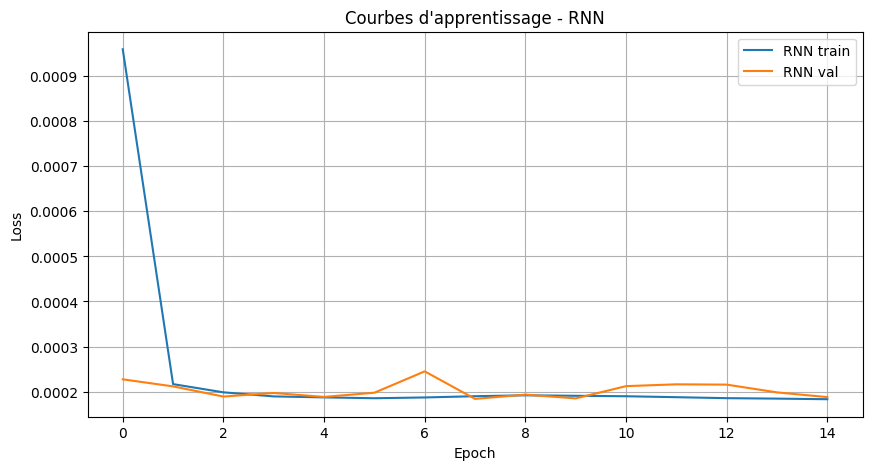

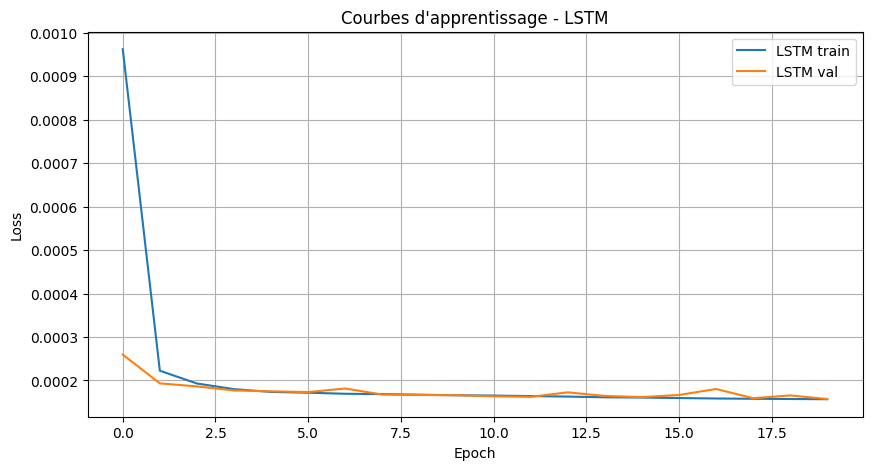

In [16]:
# Q8) courbes d'apprentissage

plt.figure(figsize=(10, 5))
plt.plot(history_rnn.history["loss"], label="RNN train")
plt.plot(history_rnn.history["val_loss"], label="RNN val")
plt.title("Courbes d'apprentissage - RNN")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()
plt.figure(figsize=(10, 5))
plt.plot(history_lstm.history["loss"], label="LSTM train")
plt.plot(history_lstm.history["val_loss"], label="LSTM val")
plt.title("Courbes d'apprentissage - LSTM")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.show()
#plt.figure(figsize=(10, 5))
#plt.plot(history_bilstm.history["loss"], label="BiLSTM train")
#plt.plot(history_bilstm.history["val_loss"], label="BiLSTM val")
#plt.title("Courbes d'apprentissage - BiLSTM")
#plt.xlabel("Epoch")
#plt.ylabel("Loss")
#plt.legend()
#plt.grid(True)
#plt.show()


### Q9 – Prédictions sur le test set, Inverse Scaling et Métriques

In [17]:
#Prédiction sur le test set
y_pred_rnn = model_rnn.predict(X_test)
y_pred_lstm = model_lstm.predict(X_test)
#y_pred_bilstm = model_bilstm.predict(X_test)
print("Shape y_pred_rnn  :", y_pred_rnn.shape)
print("Shape y_pred_lstm :", y_pred_lstm.shape)
#print("Shape y_pred_bilstm  :", y_pred_bilstm.shape)

1969/1969 ━━━━━━━━━━━━━━━━━━━━ 15s 8ms/step
1969/1969 ━━━━━━━━━━━━━━━━━━━━ 36s 18ms/step
Shape y_pred_rnn  : (63003, 10)
Shape y_pred_lstm : (63003, 10)


In [18]:
# Inverse scaling
y_test_inv = scaler.inverse_transform(y_test)

y_pred_rnn_inv = scaler.inverse_transform(y_pred_rnn)
y_pred_lstm_inv = scaler.inverse_transform(y_pred_lstm)
#y_pred_bilstm_inv = scaler.inverse_transform(y_pred_bilstm)

print("Exemple y_test_inv[0] :")
print(y_test_inv[0])

Exemple y_test_inv[0] :
[6.04 5.91 5.9  5.96 6.18 6.2  6.22 6.26 6.38 6.6 ]


In [19]:
def evaluate_multistep(y_true, y_pred, model_name="Model"):

    print(f"\n===== Évaluation de {model_name} =====")
    for h in range(y_true.shape[1]):
        true_h = y_true[:, h]
        pred_h = y_pred[:, h]

        mae = mean_absolute_error(true_h, pred_h)
        rmse = np.sqrt(mean_squared_error(true_h, pred_h))
        r2 = r2_score(true_h, pred_h)

        print(f"t+{h+1:02d} | MAE = {mae:.4f} | RMSE = {rmse:.4f} | R² = {r2:.4f}")

In [20]:
# Évaluation des trois modèles
evaluate_multistep(y_test_inv, y_pred_rnn_inv, "RNN")
evaluate_multistep(y_test_inv, y_pred_lstm_inv, "LSTM")
#evaluate_multistep(y_test_inv, y_pred_bilstm_inv, "BiLSTM")


===== Évaluation de RNN =====
t+01 | MAE = 0.1439 | RMSE = 0.2140 | R² = 0.9992
t+02 | MAE = 0.2245 | RMSE = 0.3446 | R² = 0.9980
t+03 | MAE = 0.3046 | RMSE = 0.4595 | R² = 0.9965
t+04 | MAE = 0.3965 | RMSE = 0.5760 | R² = 0.9945
t+05 | MAE = 0.4594 | RMSE = 0.6700 | R² = 0.9926
t+06 | MAE = 0.5089 | RMSE = 0.7393 | R² = 0.9910
t+07 | MAE = 0.5742 | RMSE = 0.8291 | R² = 0.9887
t+08 | MAE = 0.6437 | RMSE = 0.9178 | R² = 0.9861
t+09 | MAE = 0.7129 | RMSE = 1.0099 | R² = 0.9832
t+10 | MAE = 0.7763 | RMSE = 1.0973 | R² = 0.9801

===== Évaluation de LSTM =====
t+01 | MAE = 0.1331 | RMSE = 0.1998 | R² = 0.9993
t+02 | MAE = 0.2213 | RMSE = 0.3384 | R² = 0.9981
t+03 | MAE = 0.2945 | RMSE = 0.4447 | R² = 0.9967
t+04 | MAE = 0.3600 | RMSE = 0.5365 | R² = 0.9952
t+05 | MAE = 0.4216 | RMSE = 0.6213 | R² = 0.9936
t+06 | MAE = 0.4827 | RMSE = 0.7027 | R² = 0.9918
t+07 | MAE = 0.5401 | RMSE = 0.7801 | R² = 0.9900
t+08 | MAE = 0.5988 | RMSE = 0.8568 | R² = 0.9879
t+09 | MAE = 0.6577 | RMSE = 0.9344 |

### Q10 – Visualisation des prédictions pour les horizons t+1 à t+10

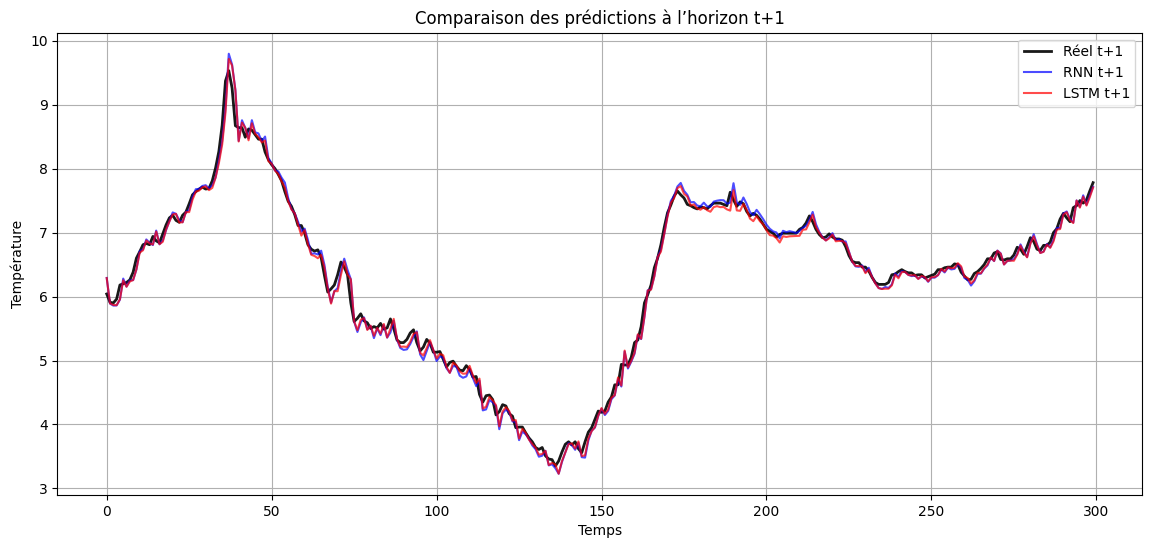

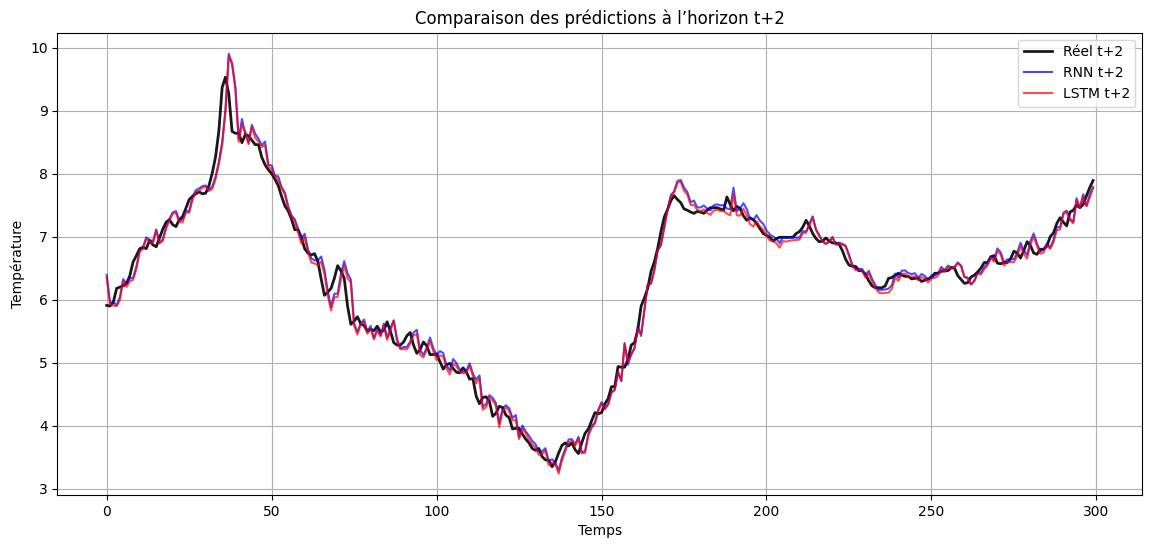

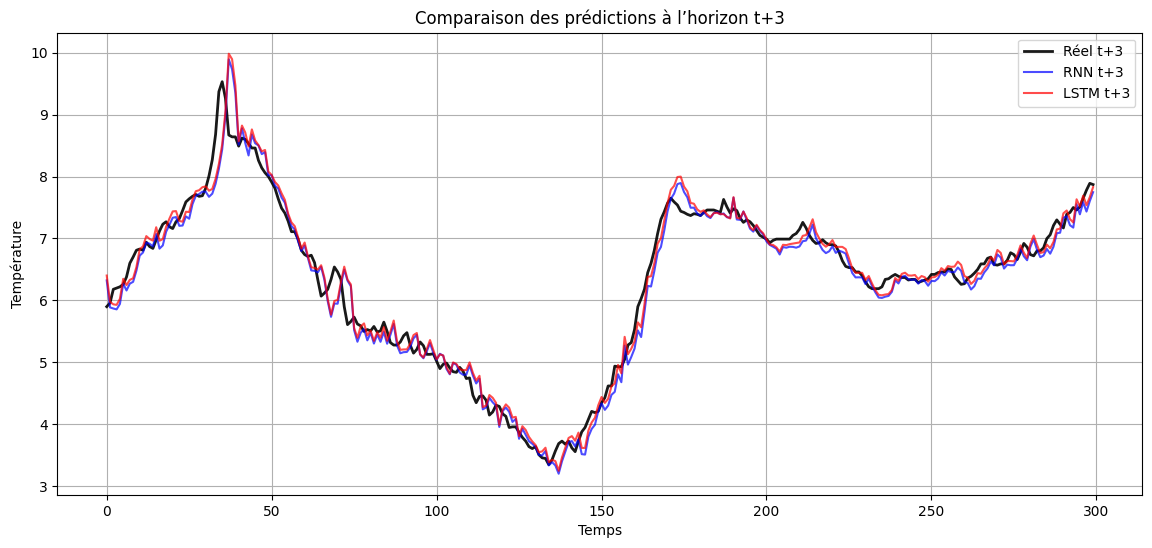

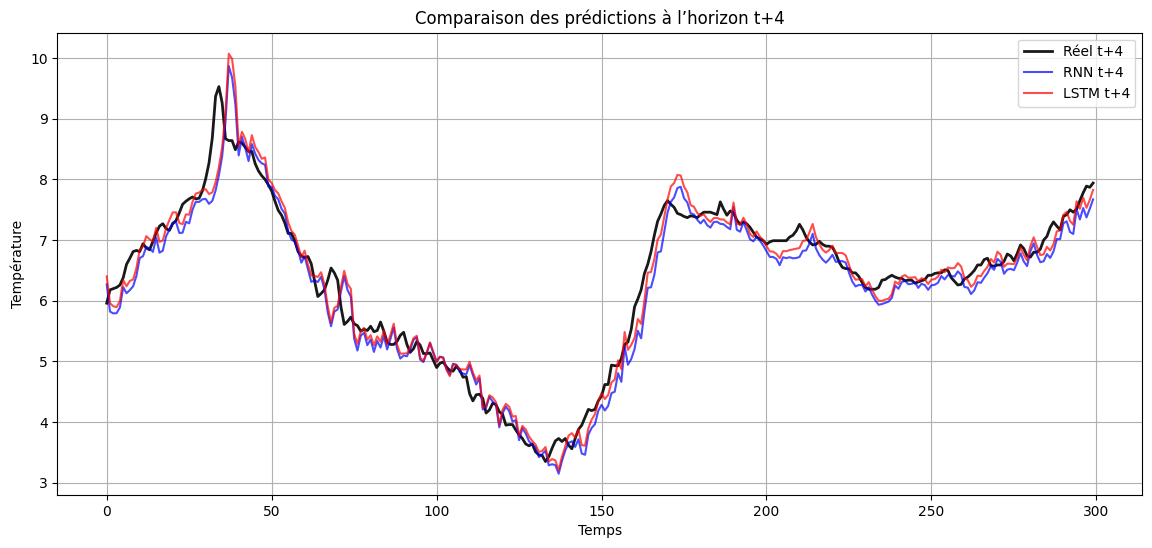

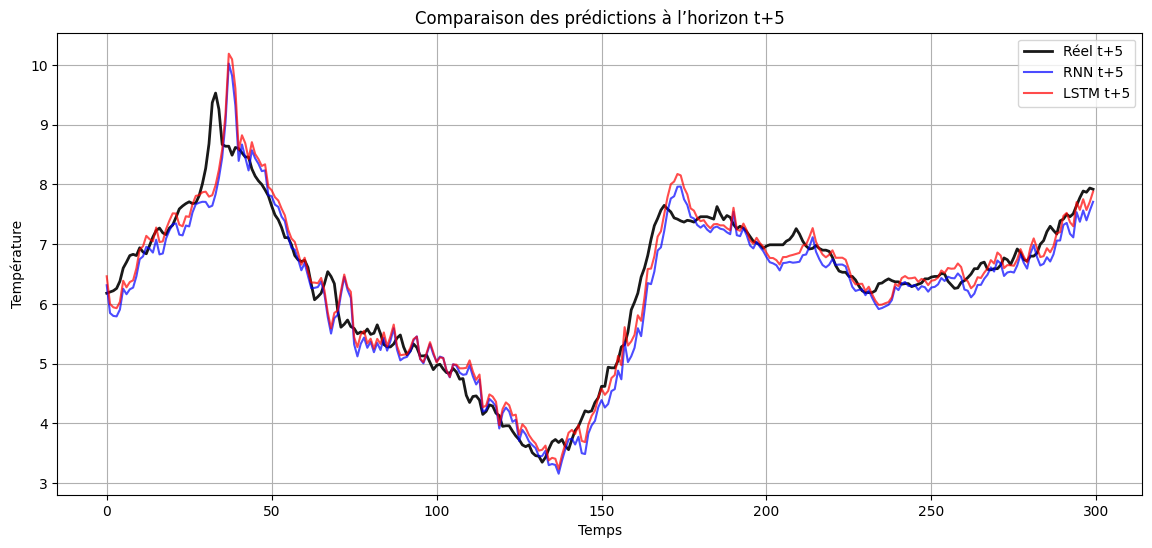

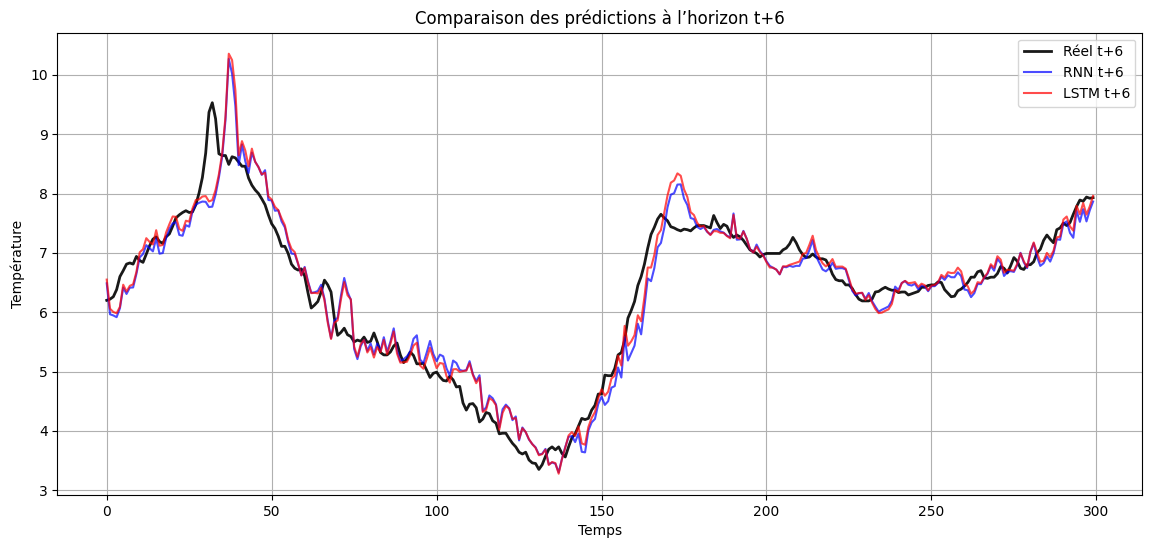

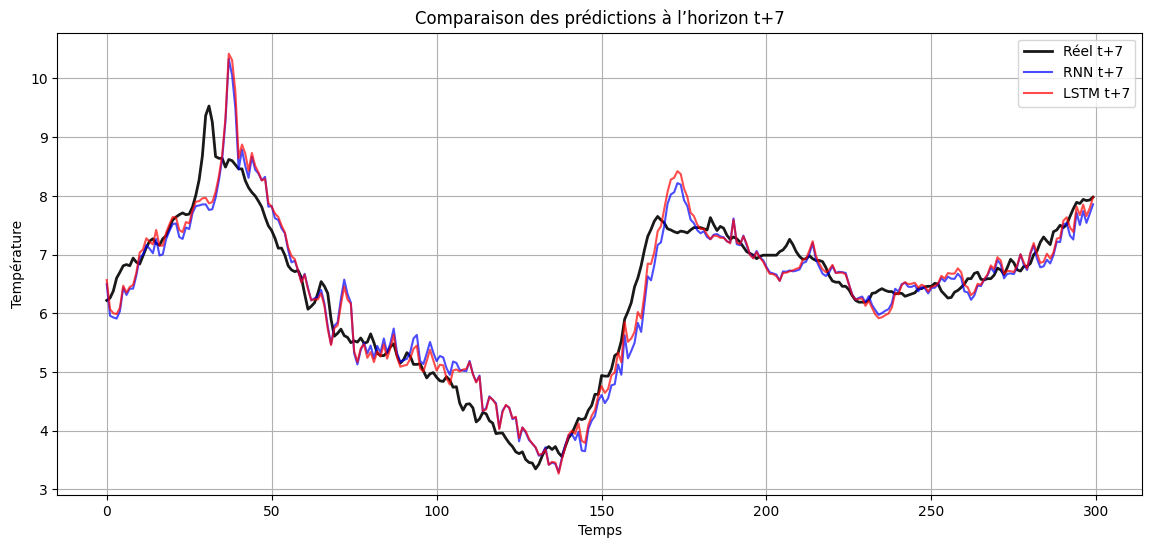

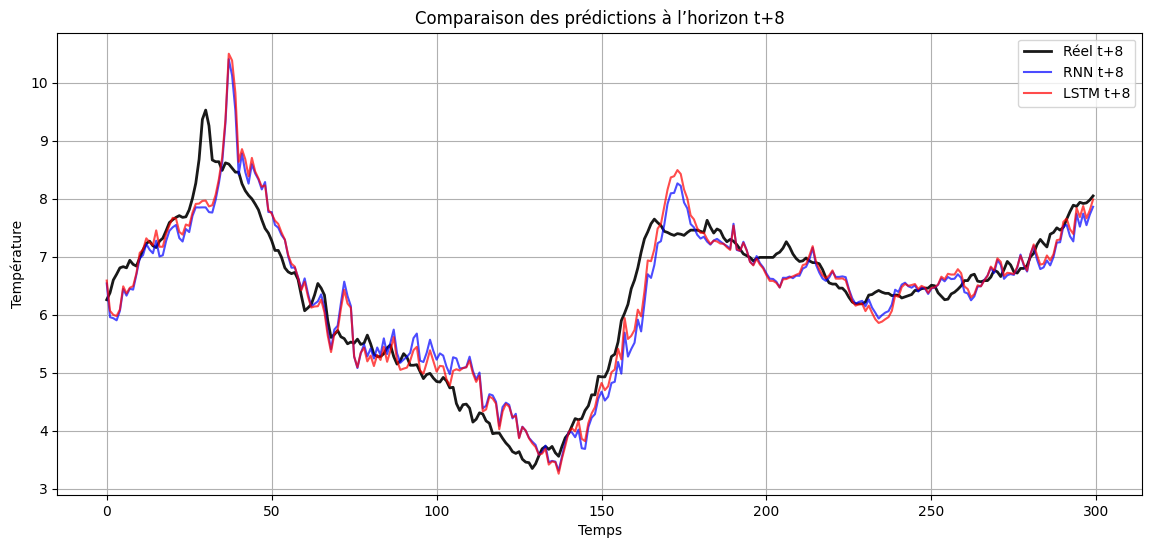

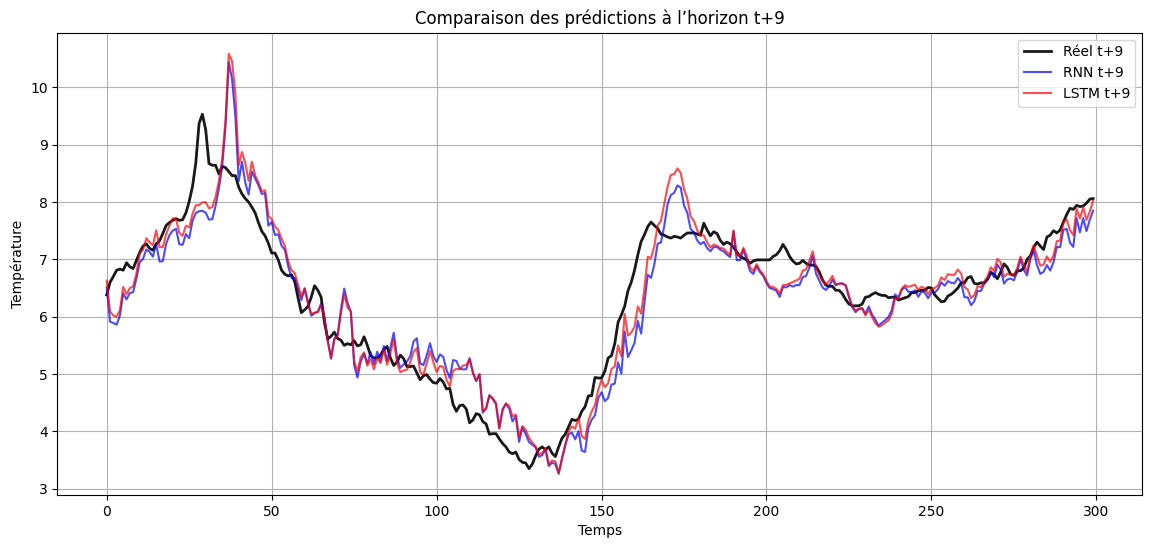

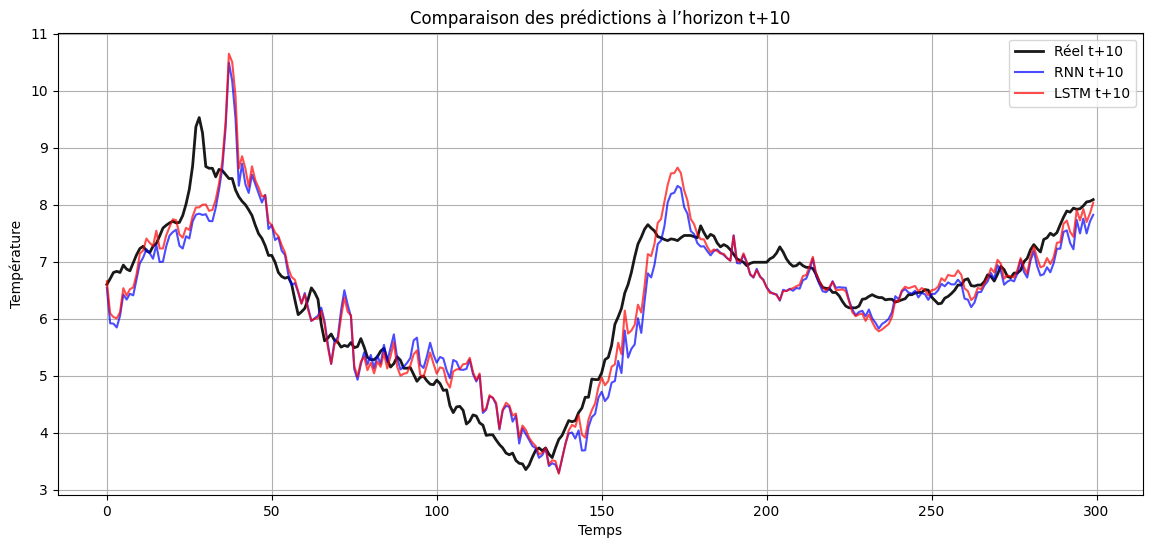

In [23]:
# Nombre de points test à afficher
n_points = 300

# Boucle sur les 10 horizons
for h in range(horizon):
    plt.figure(figsize=(14, 6))

    # Valeurs réelles
    plt.plot(y_test_inv[:n_points, h], label=f"Réel t+{h+1}", color="black", linewidth=2, alpha=0.9)

    # Prédictions des trois modèles
    plt.plot(y_pred_rnn_inv[:n_points, h], label=f"RNN t+{h+1}", color="blue", alpha=0.7)
    plt.plot(y_pred_lstm_inv[:n_points, h], label=f"LSTM t+{h+1}", color="red", alpha=0.7)

    plt.title(f"Comparaison des prédictions à l’horizon t+{h+1}")
    plt.xlabel("Temps")
    plt.ylabel("Température")
    plt.legend()
    plt.grid(True)
    plt.show()

---
# PARTIE II – Questions de réflexion

**Q12. Pourquoi la prédiction à 10 pas est-elle plus difficile que la prédiction à 1 pas ?**

La prédiction à 10 pas est plus difficile que celle à 1 pas car elle implique une projection plus lointaine dans le futur, ce qui augmente fortement l’incertitude. À 1 pas, le modèle prédit une valeur très proche des données observées, donc il bénéficie directement de l’information récente contenue dans la fenêtre d’entrée. En revanche, à 10 pas, l'incertitude s'accumule.

**Q13. Pourquoi est-il nécessaire de revenir à l'échelle originale avant d'évaluer les prédictions ?**

Les métriques (MAE, RMSE) calculées sur des données normalisées [0, 1] n'ont pas de sens physique. L'inverse scaling est donc indispensable pour les raisons suivantes:

1. **Interprétabilité physique** : une MAE de 0.02 dans l'espace normalisé n'a aucune signification directe. Après inverse scaling, une MAE de 0.8°C est immédiatement interprétable par rapport au domaine météorologique.

2. **comparabilité** : si l'on calcule MAE/RMSE dans l'espace normalisé, les résultats dépendent de l'amplitude des données (min/max du dataset). **Des datasets avec des gammes différentes** ne seraient pas comparables. L'espace physique est la référence neutre. De même, po**ur comparer les performances de différents modèles**, les métriques doivent être dans l'unité d'origine (ici, les degrés Celsius).

**Q14). À l’aide d’une recherche, expliquer le fonctionnement du modèle LSTM bidirectionnel.** Le modèle utilisé repose sur une couche LSTM bidirectionnelle (BiLSTM), qui étend le principe du LSTM classique en analysant chaque séquence temporelle dans deux sens simultanément : un premier LSTM traite la séquence dans le sens chronologique (du passé vers le futur), tandis qu’un second LSTM la parcourt en sens inverse (du futur vers le passé). Ainsi, à chaque instant, le modèle ne s’appuie plus uniquement sur les informations passées, mais combine deux représentations complémentaires : l’une issue du passé et l’autre intégrant également le contexte futur, ce qui permet de capturer des dépendances temporelles plus riches et plus globales.

Dans l’implémentation utilisée Bidirectional(LSTM(64)), il est important de comprendre que les 64 neurones sont appliqués dans chaque direction. Autrement dit, le LSTM forward possède 64 unités et le LSTM backward possède également 64 unités. Les sorties des deux directions sont ensuite concaténées, ce qui donne une représentation finale de dimension 128. Cette représentation enrichie est ensuite transmise à une couche dense qui permet de produire les 10 valeurs futures à prédire (horizon de prévision).